Restarted .venv01 (3.13.11) (Python 3.13.11)

GRU bundles saved: [2019, 2020, 2021]
gru_action
no_trade          3097
short_straddle    2908
long_straddle     2240
NaN                289
short_strangle     215
long_strangle       11
Name: count, dtype: int64
count    5.374000e+03
mean     6.734224e-04
std      9.470572e-04
min      3.525638e-07
25%      1.840745e-04
50%      4.198625e-04
75%      8.147359e-04
max      6.271358e-03
Name: gru_best_score, dtype: float64
       gru_long_straddle  gru_short_straddle  gru_long_strangle  \
count        8471.000000         8471.000000        8471.000000   
mean           -0.000420           -0.000395          -0.000325   
std             0.001148            0.001255           0.000767   
min            -0.002750           -0.008348          -0.001868   
25%            -0.001136           -0.000798          -0.000744   
50%            -0.000444           -0.000304          -0.000338   
75%             0.000029            0.000313          -0.000088   
max             0.006271            0.

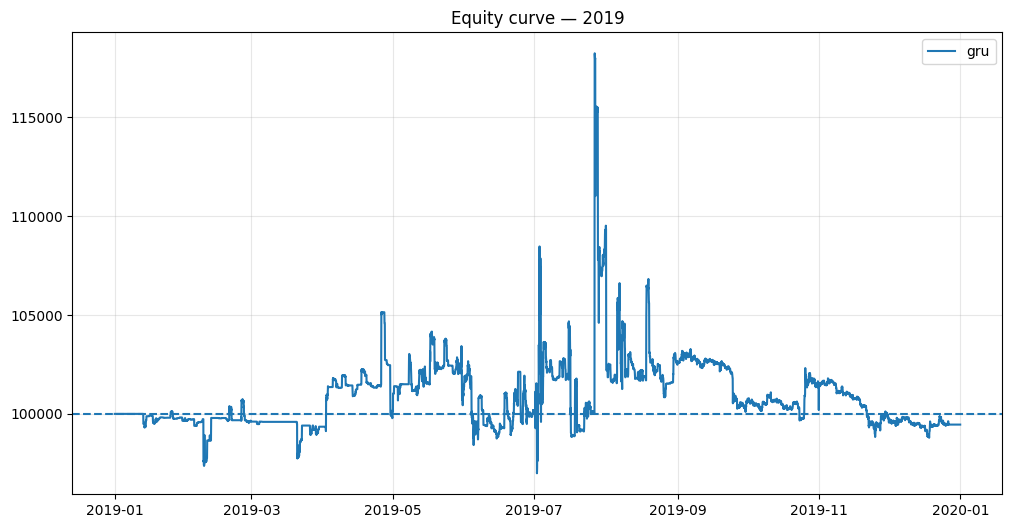

   year     n  mean_target  target_sharpe  profitable
0  2019  2182     0.000510       0.187367    0.388634
1  2020  4058     0.000611       0.212662    0.586496
2  2021  4943     0.000579       0.249109    0.548857
   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019     1446                 220                  129         0.586364   
1  2020     3624                 634                  397         0.626183   
2  2021     4033                 496                  383         0.772177   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0    0.232222         0.123553        0.243871  
1           1.0    0.225645         0.261677        0.223726  
2           1.0    0.277730         0.300138        0.275283  
 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 290    0.000074     0.000060  0.022567    0.427586
 2019          1 289    0.000251     0.000104  0.039984    0.501730
 2019          

In [ ]:
# ANALYSIS GRU
# SEARCH WORDS :
# YEARLY_GRU_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# GRU_TRADER_DIAGNOSTICS
# GRU_FITTED_TARGET_SPACE_PERFORMANCE
# GRU_TARGET_PERFORMANCE_EXECUTED_VS_SKIPPED
# GRU_SCORE_CALIBRATION_DIAGNOSTIC
# GRU_SCORE_THRESHOLD_CALIBRATION
# GRU_SCORE_THRESHOLD_TRADER_CALIBRATION


import pandas as pd
import numpy as np
import warnings
import os, sys
import pickle

from pathlib import Path
from arch.utility.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)


# =============================================================================================================
# ======================================= LOAD BASE OUTPUTS ===================================================
# =============================================================================================================
# Starts from the completed MFIV TCN output file.

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)

# =============================================================================================================
# ======================================= IMPORTS FROM SRC ====================================================
# =============================================================================================================

from srcB.market import *
from srcB.helpers import *


# =============================================================================================================
# ======================================= READ D_BTC AND DF ===================================================
# =============================================================================================================

DATA_DIR = Path("../data/rawData")

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")


# =============================================================================================================
# ======================================= SET INDEX TO DATETIME ===============================================
# =============================================================================================================

for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(
        pd.to_datetime(d_btc_raw_by_year[y]["date_time"])
    )
    df_raw_by_year[y] = df_raw_by_year[y].set_index(
        pd.to_datetime(df_raw_by_year[y]["date_time"])
    )


# =============================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR =====================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl",
    "rb"
) as f:
    X_by_year = pd.read_pickle(f)

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[
        f"{y}-01-01" : f"{y}-03-31 23:59:59"
    ].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[
        f"{y}-04-01" : f"{y}-06-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[
        f"{y}-07-01" : f"{y}-09-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[
        f"{y}-10-01" : f"{y}-12-31 23:59:59"
    ].copy()


# =============================================================================================================
# ======================================= MFIV SCALING ========================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ==========================
# =============================================================================================================

MFIVS = list(range(2, 577))

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0


# =============================================================================================================
# ======================================= BORROW RFR COLUMN ===================================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl",
    "rb"
) as f:
    d_btc_by_year = pickle.load(f)

for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(
        d_btc_raw_by_year[y].index,
        method="ffill"
    )


# =============================================================================================================
# ======================================= CHECKPOINT 1 ========================================================
# =============================================================================================================






# =============================================================================================================
# ======================================= LOAD GRU PARAMETERS =================================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/gru_best_params.pkl","rb") as f:
    best_gru_params = pickle.load(f)

SEED = 11
FORWARD_HOURS = 24


# ======================================= CHECK HPO RESULTS =================================================
# with open(
#     "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/gru_study.pkl","rb"
# ) as f:
#     gru_study = pickle.load(f)

# print(gru_study.best_value)
# print(gru_study.best_params)

# df = gru_study.trials_dataframe()

# print(df.groupby("params_hidden_size")["value"].agg(["mean", "min", "count"]))
# print(df.groupby("params_batch_size")["value"].agg(["mean", "min", "count"]))

# =============================================================================================================
# ======================================= YEARLY_GRU_ESTIMATION ===============================================
# =============================================================================================================

sys.modules.pop("srcB.gru_model_mfiv", None)
from srcB.gru_model_mfiv import *

gru_bundle_by_year = {}
gru_targets_by_year = {}
gru_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    gru_output, gru_bundle, gru_targets = gru_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=FORWARD_HOURS,
        delta_target=0.20,
        hidden_size=best_gru_params["hidden_size"],
        num_layers=best_gru_params["num_layers"],
        dropout=best_gru_params["dropout"],
        # epochs=best_gru_params["epochs_by_year"][y],
        epochs= 40,
        batch_size=best_gru_params["batch_size"],
        learning_rate=best_gru_params["learning_rate"],
        weight_decay=best_gru_params["weight_decay"],
        seed=SEED
    )

    gru_output_by_year[y] = gru_output
    gru_bundle_by_year[y] = gru_bundle
    gru_targets_by_year[y] = gru_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        gru_q = gru_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q],gru_q], axis=1)


# =============================================================================================================
# ======================================= SAVE GRU BUNDLES ====================================================
# =============================================================================================================

os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/GRU",exist_ok=True)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/GRU/gru_bundle_by_year.pkl","wb") as f:
    pickle.dump(gru_bundle_by_year, f)

print("GRU bundles saved:", list(gru_bundle_by_year.keys()))


# =============================================================================================================
# ======================================= SAVE OUTPUTS ========================================================
# =============================================================================================================
# Save before the runtime trader adapter so the real TCN columns remain untouched in the cumulative file.

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_05.pkl","wb") as f:
    pickle.dump(outputs_by_year, f)


# =============================================================================================================
# ======================================= CHECKPOINT 2 - TRADER ONLY =========================================
# =============================================================================================================

# with open(
#     "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_05.pkl",
#     "rb"
# ) as f:
#     outputs_by_year = pickle.load(f)


# =============================================================================================================
# ======================================= PREPARE TRADER INPUT ================================================
# =============================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )

        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )


# =============================================================================================================
# ======================================= GRU TRADER ADAPTER ==================================================
# =============================================================================================================
# GRU signals are not altered. The existing trader reads the TCN interface names,
# so only the action and score columns are copied for this runtime trader pass.

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["gru_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["gru_best_score"]


# =============================================================================================================
# ======================================= CACHE FOR WARMUP ====================================================
# =============================================================================================================

CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"

if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }

if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]

### DELTE CHECK
x = pd.concat([
    outputs_by_year[2019][q][["gru_action", "gru_best_score"]]
    for q in QUARTERS
]).sort_index()

print(x["gru_action"].value_counts(dropna=False))
print(x.loc[x["gru_action"] != "no_trade", "gru_best_score"].describe())

score_cols = [
    "gru_long_straddle",
    "gru_short_straddle",
    "gru_long_strangle",
    "gru_short_strangle"
]
x = gru_output_by_year[2019][score_cols]
print(x.describe())
print(x.max(axis=1).describe())
# =============================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE =============================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn_v1", None)
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy

MODEL = "gru"
RUN_BY = "year"
strategy_results = {}

for YEAR in YEARS:

    market = Market(
        option_df=df_raw_by_year[YEAR],
        time_df=d_btc_raw_by_year[YEAR],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    greek_tests = []
    yearly_snapshots = []

    if RUN_BY == "year":
        periods = [None]
    else:
        periods = ["q1", "q2", "q3", "q4"]

    for q in periods:
        snapshots, greek_tests_q = testing_execute_trading_strategy(
            bt_year=YEAR,
            bt_quarter=q,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by=RUN_BY,
            quantity=10,
            expiry_days=30,
            hold_days=7,
            lookback_hours=168,
            mean_hours=12,
            ql=0.10,
            qh=0.90,
            z=1.645,
            forward_hours = FORWARD_HOURS
        )

        greek_tests.extend(greek_tests_q)
        yearly_snapshots.extend(snapshots)

    # Guard for 0 transactions in a year
    if len(market.transactions) == 0:
        raise RuntimeError(f"GRU main IS trader produced zero transactions in {YEAR}, go to section TESTING_MAIN_WITH_CACHE")
    
    history_key = f"{MODEL}_{str(YEAR)[2:]}"
    equity_curve = market.get_equity_history()

    strategy_results[history_key] = {
        "equity_curve": equity_curve,
        "snapshots": yearly_snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

print(YEAR, MODEL)


# =============================================================================================================
# ======================================= BASIC CHECKS ========================================================
# =============================================================================================================

print(len(greek_tests))
print(greek_tests[:1])
print(pd.Series([x["action"] for x in market.transactions]).value_counts())
print("outputs:", "gru_action" in outputs_by_year[2019]["q1"].columns)
print("adapter:", "tcn_action" in outputs_by_year[2019]["q1"].columns)
print("cache:", "tcn_action" in trader_cache[2019].columns)
[c for c in trader_cache[2019].columns if c.startswith("gru")]


# =============================================================================================================
# ======================================= SAVE STRATEGY RESULTS ===============================================
# =============================================================================================================

os.makedirs(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results",
    exist_ok=True
)

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results_gru.pkl",
    "wb"
) as f:
    pickle.dump(strategy_results, f)


# =============================================================================================================
# ======================================= SHARPE ===============================================================
# =============================================================================================================

rows = []

for y in YEARS:
    history_key = f"gru_{str(y)[2:]}"
    snapshots = strategy_results[history_key]["snapshots"]

    equity = pd.Series(
        [s["equity"] for s in snapshots],
        index=[s["time"] for s in snapshots]
    )

    returns = equity.pct_change().dropna()
    sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

    rows.append({
        "year": y,
        "model": "gru",
        "sharpe": sharpe
    })

sharpe_table = pd.DataFrame(rows)
print(sharpe_table)


# =============================================================================================================
# ======================================= PLOT EQUITY ==========================================================
# =============================================================================================================

import matplotlib.pyplot as plt

PLOT_YEAR = 2019
plot_key = f"gru_{str(PLOT_YEAR)[2:]}"
result = strategy_results[plot_key]
eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")

plt.figure(figsize=(12, 6))
plt.plot(eq["time"], eq["equity"], label="gru")
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# =============================================================================================================
# ======================================= PHASE 2: DIAGNOSTICS FOR GRU =======================================
# =============================================================================================================


# =============================================================================================================
# ================================ GRU FITTED TARGET-SPACE PERFORMANCE ========================================
# =============================================================================================================
# Target-space Sharpe here is mean/std and is not annualized.

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:
    test = pd.concat([
        gru_output_by_year[y][["gru_action"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    realized = pd.Series(0.0, index=test.index)

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["gru_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]

    sharpe = realized.mean() / realized.std()

    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })

target_sharpe = pd.DataFrame(rows)
print(target_sharpe)


# =============================================================================================================
# ================================ GRU TARGET PERFORMANCE: EXECUTED VS SKIPPED ================================
# =============================================================================================================
# Question: does the sequential trader execute a representative subset of the GRU's fitted opportunities?

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        gru_output_by_year[y][["gru_action"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["gru_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["gru_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"gru_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["gru_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries) if len(entries) else np.nan,
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)
print(execution_check)


# =============================================================================================================
# ======================================= GRU SCORE CALIBRATION DIAGNOSTIC ===================================
# =============================================================================================================
# Question: are higher GRU score bins associated with better realized target outcomes?

rows = []

for y in YEARS:
    test = pd.concat([
        gru_output_by_year[y][["gru_action", "gru_best_score"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["gru_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["gru_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    test["score_bin"] = pd.qcut(
        test["gru_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("gru_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

In [ ]:
# =============================================================================================================
# ======================================= GRU SCORE THRESHOLD CALIBRATION ====================================
# =============================================================================================================
# Question: if only signals with gru_best_score >= threshold are retained, does fitted target performance improve?

tests = {}

for y in YEARS:

    x = pd.concat([
        gru_output_by_year[y][["gru_action", "gru_best_score"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["gru_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["gru_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x

scores_all = pd.concat([
    tests[y]["gru_best_score"]
    for y in YEARS
])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["gru_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)
print(threshold_check.to_string(index=False))

 quantile    threshold  year    n  mean_target   sharpe
     0.00 9.022187e-10  2019 1446     0.000770 0.232222
     0.00 9.022187e-10  2020 3624     0.000684 0.225645
     0.00 9.022187e-10  2021 4033     0.000710 0.277730
     0.20 1.417045e-04  2019 1178     0.000941 0.275882
     0.20 1.417045e-04  2020 3088     0.000803 0.250773
     0.20 1.417045e-04  2021 3016     0.000898 0.331174
     0.40 2.703784e-04  2019  978     0.001101 0.310770
     0.40 2.703784e-04  2020 2213     0.001115 0.304752
     0.40 2.703784e-04  2021 2271     0.001127 0.393607
     0.50 3.529540e-04  2019  854     0.001235 0.339377
     0.50 3.529540e-04  2020 1792     0.001354 0.342276
     0.50 3.529540e-04  2021 1906     0.001253 0.427997
     0.60 4.634357e-04  2019  741     0.001408 0.379086
     0.60 4.634357e-04  2020 1420     0.001657 0.384307
     0.60 4.634357e-04  2021 1480     0.001497 0.491438
     0.70 6.305333e-04  2019  562     0.001681 0.424079
     0.70 6.305333e-04  2020 1086     0.002035 0

In [ ]:
# 5===== Does the threshold improvement survive the actual sequential trader? =====
# ================================ GRU_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn_v1", None)
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]
rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold,
            forward_hours=FORWARD_HOURS
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades   sharpe
  0.000000  2019     220 0.115692
  0.000000  2020     634 0.084577
  0.000000  2021     496 0.642748
  0.000631  2019     167 0.588204
  0.000631  2020     239 1.242666
  0.000631  2021     229 0.799153
  0.000895  2019     119 0.262464
  0.000895  2020     153 1.008386
  0.000895  2021     164 0.436187
  0.001078  2019     103 0.041615
  0.001078  2020     135 0.881554
  0.001078  2021     126 1.300594
  0.001364  2019      57 0.319038
  0.001364  2020      96 1.080369
  0.001364  2021      96 1.745074
